# Exploratory Data Analysis: Superstore Retail Sales
**Goal:** data wrangling, missing-value profiling, and commercial sales distributions.
**Focus areas:** customer purchase volume, monthly seasonality, category-wise revenue, discount sensitivity.
**Tools:** Python (Pandas, Matplotlib, Seaborn)

**Notebook flow:** 1) Load and inspect, 2) Wrangle, 3) Feature engineering, 4) EDA, 5) Executive takeaways

In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5)
pd.options.display.float_format = '{:,.2f}'.format

FILE = 'superstore_sales.csv'   # update the path if needed

## 1. Load and inspect the raw file

In [ ]:
raw = pd.read_csv(FILE, encoding='latin1', dtype=str)
print('Raw shape:', raw.shape)
raw.head()

Raw shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0,219.582
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.031
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.368,2,0.2,2.5164


### Missing-value profiling (raw)
The raw file shows ~806 rows that are null in almost every column. That is **not random missingness**: it is a structural artefact. Let us look at the tail of the file.

In [ ]:
raw_nulls = raw.isna().sum()
print(raw_nulls[raw_nulls > 0])
print()
raw.iloc[9990:9998, :3]

Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64



,Row ID,Order ID,Order Date
9990,9991,CA-2018-121258,2/26/2018
9991,9992,CA-2018-121258,2/26/2018
9992,9993,CA-2018-121258,2/26/2018
9993,9994,CA-2018-119914,5/4/2018
9994,Person,Region,NaN
9995,Anna Andreadi,West,NaN
9996,Chuck Magee,East,NaN
9997,Kelly Williams,Central,NaN


The CSV is actually **three tables stacked in one file** (probably exported from a multi-sheet Excel workbook):
1. Orders (the real data, 9,994 rows)
2. A `Person` / `Region` lookup (regional managers)
3. A `Returned` / `Order ID` table (returned orders)

The second and third tables are what produce the 806 "empty" rows when read under the orders header. We split them apart using their header rows as markers.

In [ ]:
i_people  = raw.index[raw['Row ID'] == 'Person'][0]
i_returns = raw.index[raw['Row ID'] == 'Returned'][0]

orders  = raw.iloc[:i_people].copy()
people  = raw.iloc[i_people + 1:i_returns, :2].copy()
people.columns = ['Person', 'Region']
returns = raw.iloc[i_returns + 1:, :2].copy()
returns.columns = ['Returned', 'Order ID']

orders  = orders.dropna(how='all')
people  = people.dropna(how='all')
returns = returns.dropna(how='all')

print('orders :', orders.shape)
print('people :', people.shape)
print('returns:', returns.shape, '| unique returned orders:', returns['Order ID'].nunique())
people

orders : (9994, 21)
people : (4, 2)
returns: (800, 2) | unique returned orders: 296


,Person,Region
9995,Anna Andreadi,West
9996,Chuck Magee,East
9997,Kelly Williams,Central
9998,Cassandra Brandow,South


## 2. Data wrangling

In [ ]:
df = orders.copy()

# 2.1 Types
num_cols = ['Sales', 'Quantity', 'Discount', 'Profit']
df[num_cols] = df[num_cols].apply(pd.to_numeric)
df['Row ID'] = df['Row ID'].astype(int)
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%m/%d/%Y')
df['Ship Date']  = pd.to_datetime(df['Ship Date'],  format='%m/%d/%Y')

# 2.2 Remaining missing values (after the split)
print('Remaining nulls:')
print(df.isna().sum()[lambda s: s > 0])

Remaining nulls:
Postal Code    11
dtype: int64


Only `Postal Code` has gaps. Let us see where they are.

In [ ]:
df['Postal Code'] = df['Postal Code'].str.replace(r'\.0$', '', regex=True)
missing_pc = df[df['Postal Code'].isna()]
print(missing_pc[['City', 'State']].drop_duplicates())

            City    State
2234  Burlington  Vermont


In [ ]:
# All missing postal codes are Burlington, Vermont -> impute its ZIP (05401)
df.loc[df['Postal Code'].isna() & (df['City'] == 'Burlington'), 'Postal Code'] = '05401'
df['Postal Code'] = df['Postal Code'].str.zfill(5)   # restore leading zeros
print('Nulls left:', int(df.isna().sum().sum()))

# 2.3 Duplicates (ignoring the surrogate Row ID)
dupes = df.duplicated(subset=[c for c in df.columns if c != 'Row ID'], keep='first')
print('Exact duplicate rows:', dupes.sum())
df = df[~dupes].reset_index(drop=True)

# 2.4 Sanity checks
assert (df['Ship Date'] >= df['Order Date']).all(), 'Ship date before order date!'
print('Sales <= 0 :', (df['Sales'] <= 0).sum())
print('Discount range:', df['Discount'].min(), '-', df['Discount'].max())
print('Date range:', df['Order Date'].min().date(), '->', df['Order Date'].max().date())
print('Clean shape:', df.shape)

Nulls left: 0
Exact duplicate rows: 1
Sales <= 0 : 0
Discount range: 0.0 - 0.8
Date range: 2015-01-03 -> 2018-12-30
Clean shape: (9993, 21)


**Cleaning log**
| Issue | Action |
|---|---|
| 3 tables stacked in 1 CSV (806 structurally null rows) | Split into `orders`, `people`, `returns` |
| Dates stored as text (`m/d/Y`) | Parsed to `datetime64` |
| Numeric columns read as text | Cast to numeric |
| 11 missing `Postal Code` (all Burlington, VT) | Imputed with ZIP 05401 |
| Postal codes lost leading zeros | Stored as 5-char strings |
| 1 exact duplicate row | Removed |

## 3. Feature engineering

In [ ]:
df['Year']       = df['Order Date'].dt.year
df['Month']      = df['Order Date'].dt.month
df['Year-Month'] = df['Order Date'].dt.to_period('M')
df['Ship Days']  = (df['Ship Date'] - df['Order Date']).dt.days
df['Margin']     = df['Profit'] / df['Sales']

# Flag returned orders (order-level flag, joined onto each line item)
returned_ids = set(returns['Order ID'])
df['Returned'] = df['Order ID'].isin(returned_ids)

# Discount bands used later
bins   = [-0.01, 0, 0.10, 0.20, 0.30, 0.50, 0.80]
labels = ['0%', '1-10%', '11-20%', '21-30%', '31-50%', '51-80%']
df['Discount Band'] = pd.cut(df['Discount'], bins=bins, labels=labels)

df.head(3)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Quantity,Discount,Profit,Year,Month,Year-Month,Ship Days,Margin,Returned,Discount Band
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,2,0.00,41.91,2017,11,2017-11,3,0.16,False,0%
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,3,0.00,219.58,2017,11,2017-11,3,0.30,False,0%
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,2,0.00,6.87,2017,6,2017-06,4,0.47,False,0%


## 4. Exploratory analysis

### 4.1 Headline KPIs

In [ ]:
total_sales  = df['Sales'].sum()
total_profit = df['Profit'].sum()
kpi = pd.Series({
    'Line items':        len(df),
    'Orders':            df['Order ID'].nunique(),
    'Customers':         df['Customer ID'].nunique(),
    'Total Sales ($)':   total_sales,
    'Total Profit ($)':  total_profit,
    'Profit Margin':     total_profit / total_sales,
    'Avg Order Value ($)': total_sales / df['Order ID'].nunique(),
    'Share of orders returned': df.drop_duplicates('Order ID')['Returned'].mean(),
})
kpi.to_frame('Value')

,Value
Line items,"9,993.00"
Orders,"5,009.00"
Customers,793.00
Total Sales ($),"2,296,919.49"
Total Profit ($),"286,409.08"
Profit Margin,0.12
Avg Order Value ($),458.56
Share of orders returned,0.06


In [ ]:
yearly = df.groupby('Year').agg(Sales=('Sales','sum'), Profit=('Profit','sum'))
yearly['Margin'] = yearly['Profit'] / yearly['Sales']
yearly['Sales YoY'] = yearly['Sales'].pct_change()
yearly

,Sales,Profit,Margin,Sales YoY
Year,,,,
2015,"483,966.13","49,556.03",0.10,NaN
2016,"470,532.51","61,618.60",0.13,-0.03
2017,"609,205.60","81,795.17",0.13,0.29
2018,"733,215.26","93,439.27",0.13,0.20


### 4.2 Category, Region and Customer Segment performance

In [ ]:
def summarise(by):
    g = df.groupby(by).agg(Sales=('Sales','sum'), Profit=('Profit','sum'),
                           Orders=('Order ID','nunique'), AvgDiscount=('Discount','mean'))
    g['Margin'] = g['Profit'] / g['Sales']
    g['Sales Share'] = g['Sales'] / g['Sales'].sum()
    return g.sort_values('Sales', ascending=False)

for col in ['Category', 'Region', 'Segment']:
    display(summarise(col))

,Sales,Profit,Orders,AvgDiscount,Margin,Sales Share
Category,,,,,,
Technology,"836,154.03","145,454.95",1544,0.13,0.17,0.36
Furniture,"741,718.42","18,463.33",1764,0.17,0.02,0.32
Office Supplies,"719,047.03","122,490.80",3742,0.16,0.17,0.31


,Sales,Profit,Orders,AvgDiscount,Margin,Sales Share
Region,,,,,,
West,"725,457.82","108,418.45",1611,0.11,0.15,0.32
East,"678,499.87","91,534.84",1401,0.15,0.13,0.30
Central,"501,239.89","39,706.36",1175,0.24,0.08,0.22
South,"391,721.91","46,749.43",822,0.15,0.12,0.17


,Sales,Profit,Orders,AvgDiscount,Margin,Sales Share
Segment,,,,,,
Consumer,"1,161,401.34","134,119.21",2586,0.16,0.12,0.51
Corporate,"706,146.37","91,979.13",1514,0.16,0.13,0.31
Home Office,"429,371.78","60,310.74",909,0.15,0.14,0.19


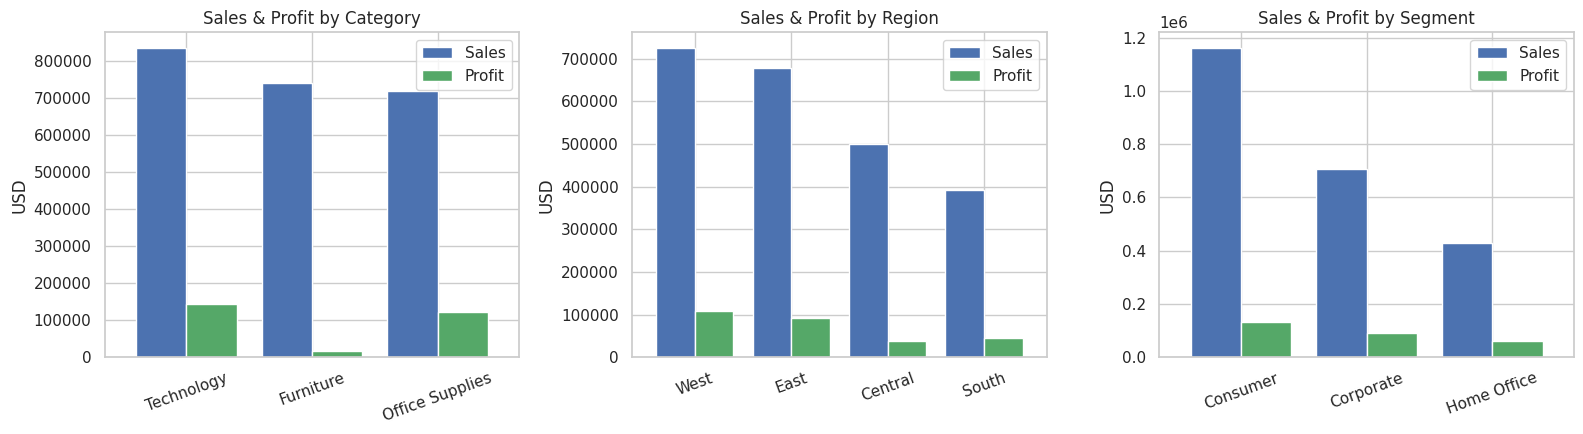

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['Category', 'Region', 'Segment']):
    g = df.groupby(col)[['Sales', 'Profit']].sum().sort_values('Sales', ascending=False)
    g.plot(kind='bar', ax=ax, color=['#4C72B0', '#55A868'], width=0.8)
    ax.set_title(f'Sales & Profit by {col}'); ax.set_xlabel(''); ax.set_ylabel('USD')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout(); plt.show()

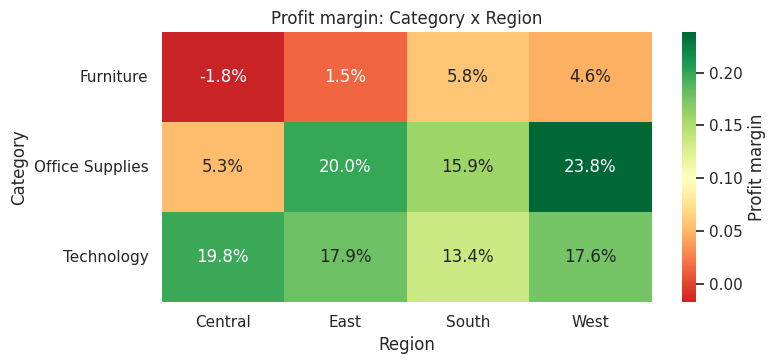

In [ ]:
# Category x Region profit margin heatmap
pivot = (df.groupby(['Category', 'Region'])[['Sales', 'Profit']].sum()
           .assign(Margin=lambda x: x['Profit'] / x['Sales'])['Margin'].unstack())
plt.figure(figsize=(8, 3.8))
sns.heatmap(pivot, annot=True, fmt='.1%', cmap='RdYlGn', center=0.1, cbar_kws={'label': 'Profit margin'})
plt.title('Profit margin: Category x Region'); plt.tight_layout(); plt.show()

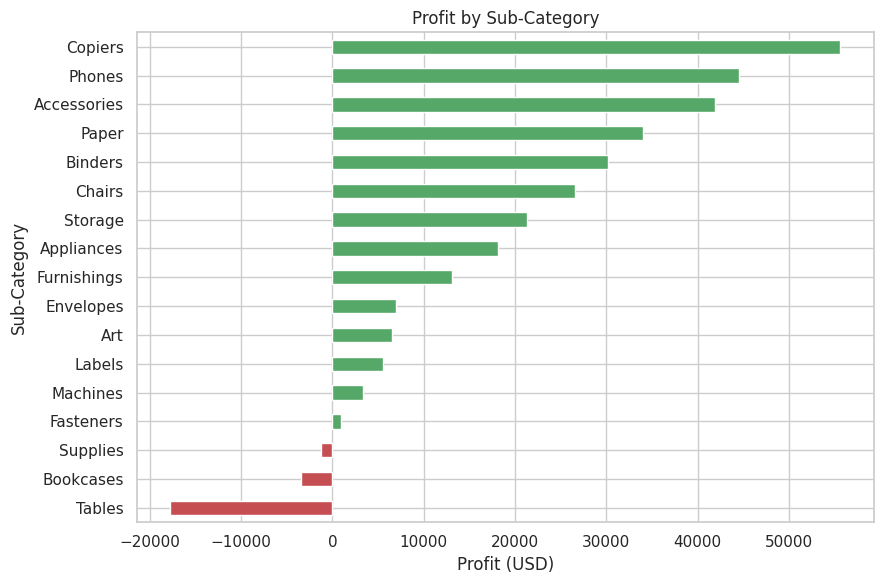

,Sales,Profit,Margin
Sub-Category,,,
Tables,"206,965.53","-17,725.48",-0.09
Bookcases,"114,880.00","-3,472.56",-0.03
Supplies,"46,673.54","-1,189.10",-0.03
Fasteners,"3,024.28",949.52,0.31
Machines,"189,238.63","3,384.76",0.02


In [ ]:
# Sub-category profitability
sub = df.groupby('Sub-Category').agg(Sales=('Sales','sum'), Profit=('Profit','sum')).sort_values('Profit')
colors = ['#C44E52' if p < 0 else '#55A868' for p in sub['Profit']]
ax = sub['Profit'].plot(kind='barh', color=colors, figsize=(9, 6))
ax.set_title('Profit by Sub-Category'); ax.set_xlabel('Profit (USD)')
plt.tight_layout(); plt.show()
sub.assign(Margin=sub['Profit']/sub['Sales']).head(5)

### 4.3 Customer purchase volume

Customers: 793
Repeat customers (2+ orders): 98.5%
Median orders / customer: 6.0
Top 10 customers share of sales: 6.7%
Top 20% customers share of sales: 48.0%


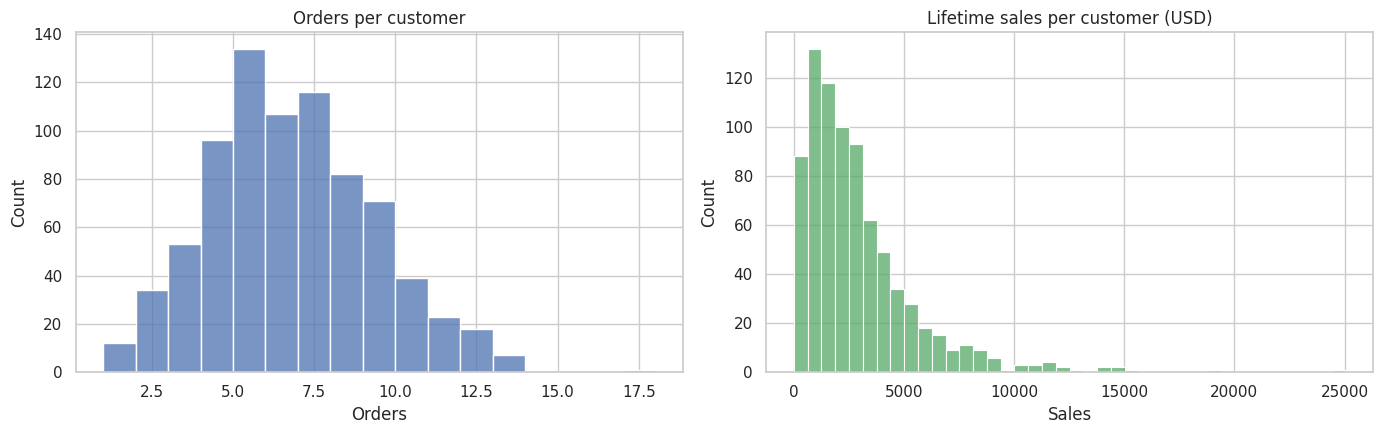

,Customer ID,Customer Name,Orders,Sales,Profit
700,SM-20320,Sean Miller,5,"25,043.05","-1,980.74"
741,TC-20980,Tamara Chand,5,"19,052.22","8,981.32"
621,RB-19360,Raymond Buch,6,"15,117.34","6,976.10"
730,TA-21385,Tom Ashbrook,4,"14,595.62","4,703.79"
6,AB-10105,Adrian Barton,10,"14,473.57","5,444.81"
434,KL-16645,Ken Lonsdale,12,"14,175.23",806.86
669,SC-20095,Sanjit Chand,9,"14,142.33","5,757.41"
327,HL-15040,Hunter Lopez,6,"12,873.30","5,622.43"
683,SE-20110,Sanjit Engle,11,"12,209.44","2,650.68"
131,CC-12370,Christopher Conant,5,"12,129.07","2,177.05"


In [ ]:
cust = df.groupby(['Customer ID', 'Customer Name']).agg(
    Orders=('Order ID','nunique'), Sales=('Sales','sum'), Profit=('Profit','sum')).reset_index()

print('Customers:', len(cust))
print('Repeat customers (2+ orders): {:.1%}'.format((cust['Orders'] >= 2).mean()))
print('Median orders / customer:', cust['Orders'].median())
print('Top 10 customers share of sales: {:.1%}'.format(cust['Sales'].nlargest(10).sum() / cust['Sales'].sum()))
print('Top 20% customers share of sales: {:.1%}'.format(cust['Sales'].nlargest(int(len(cust)*0.2)).sum() / cust['Sales'].sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(cust['Orders'], bins=range(1, 19), ax=axes[0], color='#4C72B0')
axes[0].set_title('Orders per customer')
sns.histplot(cust['Sales'], bins=40, ax=axes[1], color='#55A868')
axes[1].set_title('Lifetime sales per customer (USD)')
plt.tight_layout(); plt.show()

cust.nlargest(10, 'Sales')

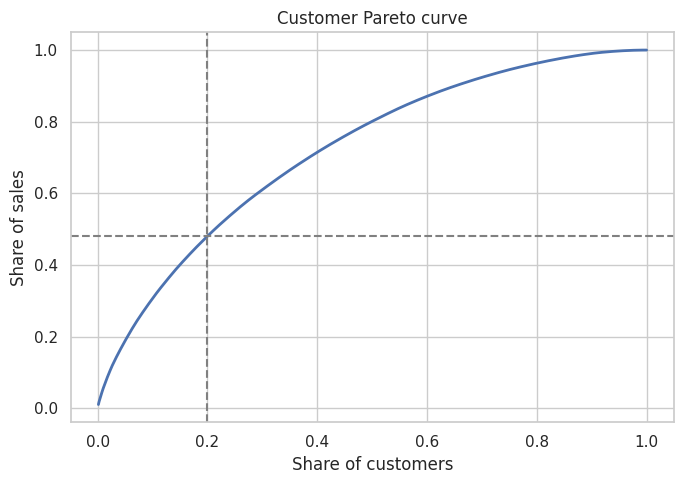

In [ ]:
# Pareto curve: cumulative share of sales vs share of customers
s = cust['Sales'].sort_values(ascending=False).reset_index(drop=True)
cum = s.cumsum() / s.sum()
x = (np.arange(len(s)) + 1) / len(s)
plt.figure(figsize=(7, 5))
plt.plot(x, cum, color='#4C72B0', lw=2)
plt.axvline(0.2, ls='--', color='grey'); plt.axhline(cum.iloc[int(len(s)*0.2)], ls='--', color='grey')
plt.xlabel('Share of customers'); plt.ylabel('Share of sales'); plt.title('Customer Pareto curve')
plt.tight_layout(); plt.show()

### 4.4 Monthly seasonality and sales velocity

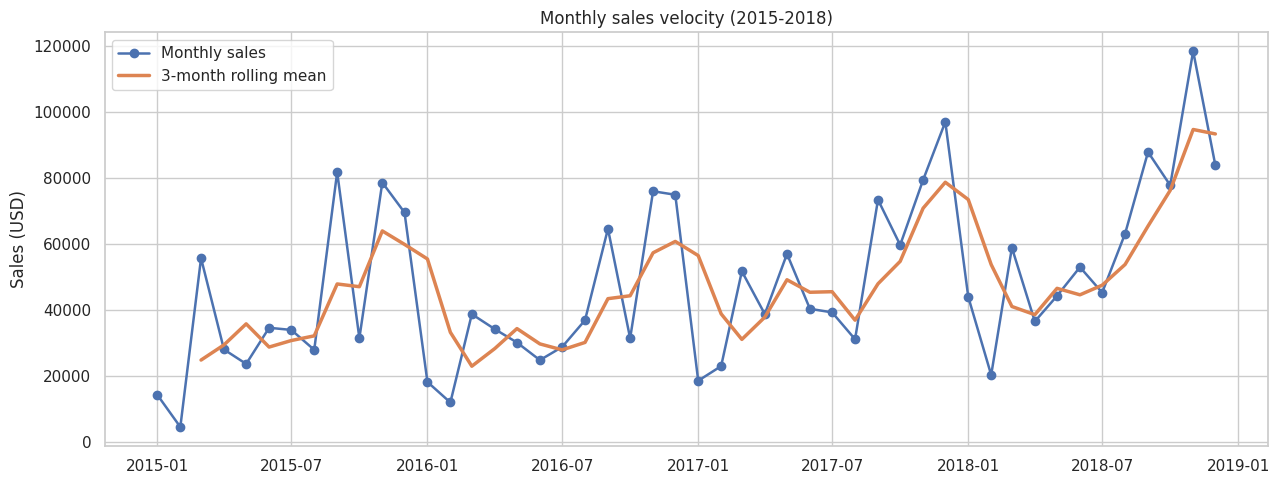

In [ ]:
monthly = df.groupby('Year-Month')['Sales'].sum()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(monthly.index, monthly.values, marker='o', lw=1.8, color='#4C72B0', label='Monthly sales')
ax.plot(monthly.index, monthly.rolling(3).mean(), lw=2.5, color='#DD8452', label='3-month rolling mean')
ax.set_title('Monthly sales velocity (2015-2018)'); ax.set_ylabel('Sales (USD)'); ax.legend()
plt.tight_layout(); plt.show()

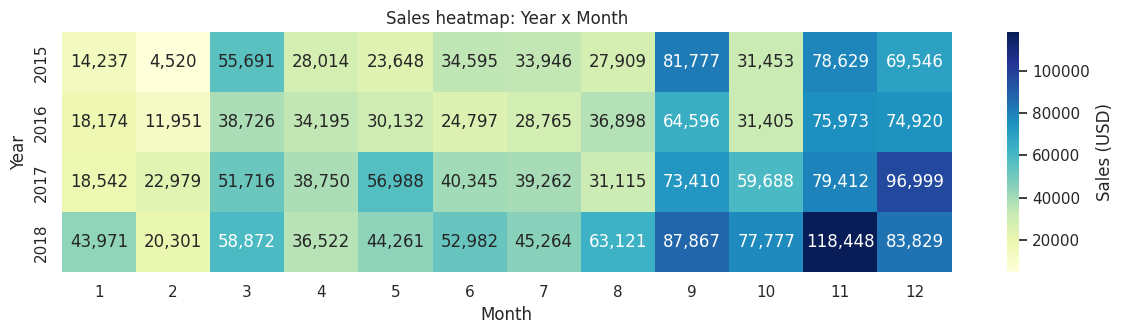

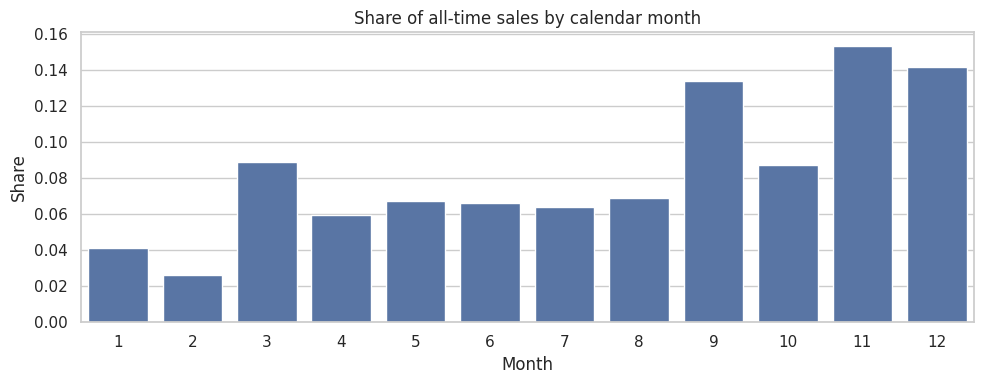

Sep-Dec share of sales: 51.6%
Jan-Feb share of sales: 6.7%


In [ ]:
heat = df.pivot_table(index='Year', columns='Month', values='Sales', aggfunc='sum')
plt.figure(figsize=(12, 3.5))
sns.heatmap(heat, annot=True, fmt=',.0f', cmap='YlGnBu', cbar_kws={'label': 'Sales (USD)'})
plt.title('Sales heatmap: Year x Month'); plt.tight_layout(); plt.show()

seasonal = df.groupby('Month')['Sales'].sum()
share = (seasonal / seasonal.sum()).rename('Share of total sales')
plt.figure(figsize=(10, 4))
sns.barplot(x=share.index, y=share.values, color='#4C72B0')
plt.title('Share of all-time sales by calendar month'); plt.ylabel('Share'); plt.xlabel('Month')
plt.tight_layout(); plt.show()
print('Sep-Dec share of sales: {:.1%}'.format(share.loc[9:12].sum()))
print('Jan-Feb share of sales: {:.1%}'.format(share.loc[1:2].sum()))

### 4.5 Discount sensitivity

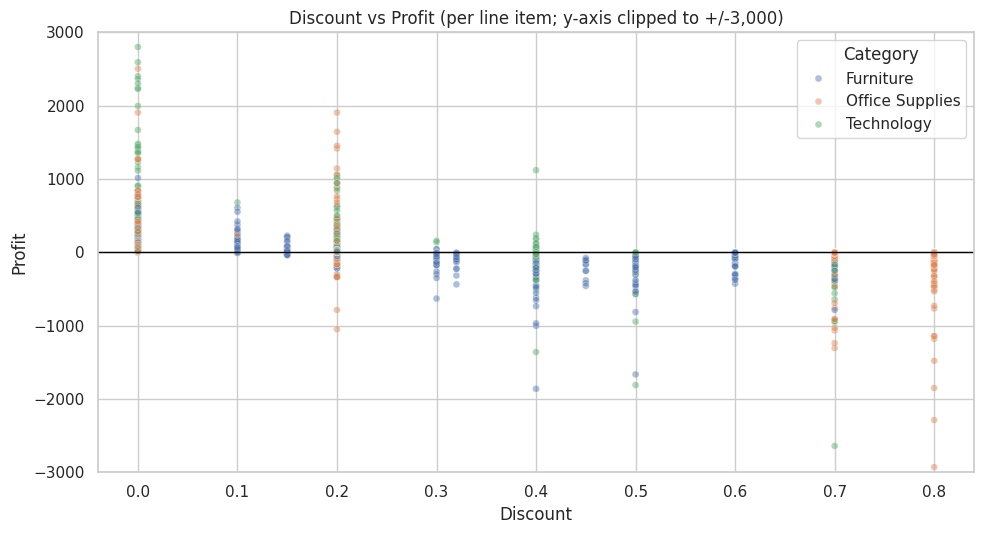

Correlation (Discount, Profit): -0.22


In [ ]:
plt.figure(figsize=(10, 5.5))
sns.scatterplot(data=df, x='Discount', y='Profit', hue='Category', alpha=0.45, s=25)
plt.axhline(0, color='black', lw=1)
plt.ylim(-3000, 3000)
plt.title('Discount vs Profit (per line item; y-axis clipped to +/-3,000)')
plt.tight_layout(); plt.show()
print('Correlation (Discount, Profit): {:.2f}'.format(df['Discount'].corr(df['Profit'])))

,LineItems,Sales,Profit,AvgProfitPerLine,Margin
Discount Band,,,,,
0%,4798,"1,087,908.47","320,987.60",66.90,0.30
1-10%,94,"54,369.35","9,029.18",96.06,0.17
11-20%,3709,"792,152.89","91,756.30",24.74,0.12
21-30%,226,"102,945.28","-10,357.22",-45.83,-0.10
31-50%,310,"195,314.76","-48,447.73",-156.28,-0.25
51-80%,856,"64,228.74","-76,559.05",-89.44,-1.19


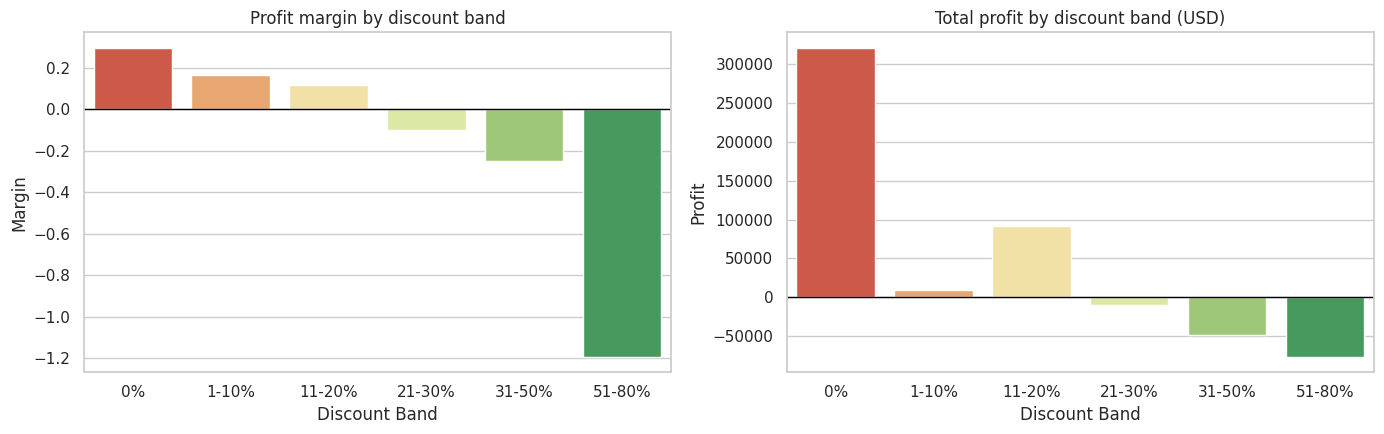

In [ ]:
band = df.groupby('Discount Band').agg(
    LineItems=('Sales', 'size'), Sales=('Sales','sum'), Profit=('Profit','sum'),
    AvgProfitPerLine=('Profit','mean'))
band['Margin'] = band['Profit'] / band['Sales']
display(band)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.barplot(x=band.index, y=band['Margin'], ax=axes[0], palette='RdYlGn')
axes[0].axhline(0, color='black', lw=1); axes[0].set_title('Profit margin by discount band')
sns.barplot(x=band.index, y=band['Profit'], ax=axes[1], palette='RdYlGn')
axes[1].axhline(0, color='black', lw=1); axes[1].set_title('Total profit by discount band (USD)')
plt.tight_layout(); plt.show()

In [ ]:
# Where does heavy discounting (>= 30%) destroy the most profit?
heavy = df[df['Discount'] >= 0.30]
heavy.groupby('Sub-Category')['Profit'].sum().sort_values().head(6)

Sub-Category
Binders      -38,510.50
Tables       -30,698.22
Machines     -29,555.35
Bookcases    -11,097.76
Appliances    -8,629.64
Chairs        -6,725.06
Name: Profit, dtype: float64

In [ ]:
# Loss-making states
df.groupby('State')['Profit'].sum().sort_values().head(5)

State
Texas            -25,729.36
Ohio             -16,959.32
Pennsylvania     -15,559.96
Illinois         -12,607.89
North Carolina    -7,490.91
Name: Profit, dtype: float64

## 5. Executive takeaways

### Finding 1: Growth is real and profitability is healthy overall
Sales grew from **$484K (2015)** to **$733K (2018)**, a 51% rise, with a 2016 dip of about 3%. Total sales are **$2.30M** with **$286K profit (12.5% margin)**. Profit grew every year, from $49.6K to $93.4K, so growth has not come at the expense of margin.

### Finding 2: Strong, predictable year-end seasonality
**September to December generates about 52% of all sales**, with November (15.3%) and December (14.2%) the two largest months. January and February are the weakest (4.1% and 2.6%). **Action:** front-load inventory, staffing and marketing spend into Sep-Dec, and use Jan-Feb for clearance and B2B outreach.

### Finding 3: Furniture is a revenue engine that earns almost no profit
Furniture sells $742K, almost the same as Office Supplies ($719K), but earns only **$18K profit (2.5% margin)** against roughly **17%** for Office Supplies and Technology. Tables (-$17.7K) and Bookcases (-$3.5K) are loss-making. **Action:** reprice or renegotiate supplier costs on Tables and Bookcases.

### Finding 4: Discounts above ~20% turn sales into losses
Orders at 0% discount earn a **29.5% margin** and those at 11-20% earn 11.6%. Beyond 20% the business loses money: **-10% margin at 21-30%, -25% at 31-50%, and -119% at 51-80%**. Discount and profit are negatively correlated (r = -0.22). **Action:** cap discounts at 20% and require approval above it. Binders, Tables and Machines lose the most under heavy discounting.

### Finding 5: A loyal, concentrated customer base
Of **793 customers**, **98% ordered more than once** and the median customer placed 6 orders, so retention is not the problem. The top 20% of customers deliver roughly **48% of sales**, which is a moderate, not extreme, concentration. **Action:** run loyalty and account-management programmes for the top quintile, and grow new-customer acquisition because the existing base is already saturated.

### Finding 6: Geographic margin gaps
**West (14.9%) and East (13.5%)** are the most profitable regions, while **Central earns only 7.9%**. Texas (-$25.7K), Ohio (-$17.0K) and Pennsylvania (-$15.6K) lose money overall, which points to discount-driven losses there. Corporate (13.0%) and Home Office (14.0%) out-earn the Consumer segment (11.5%) on margin.

### Bonus: Returns are modest
About **8% of orders** were returned, equal to about 7.9% of sales value. This is not a major leak, but the returns table is worth joining to product and region data for deeper root-cause work.